In [6]:
"""
=============================================================================
02_prepare_ml_ready_data.py
Encode, split, and balance the cleaned ENM master dataset for machine
learning (Ethiopia DHS 2024/2025, early neonatal mortality)
=============================================================================
Input:  outputs/enm_master_cleaned.csv  (from 01_clean_recode_enm_master.py)
Output: encoded train/test splits, fitted preprocessor, SMOTE-balanced
        training set -- ready to hand straight to sklearn/xgboost/etc.
=============================================================================
"""
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
import joblib
import json
import os

IN_PATH = "C:/DHS_Postnatal_Geospatial/output/ENM_ML_full_pipeline/outputs/enm_master_cleaned.csv"
OUT_DIR = "outputs"
RANDOM_STATE = 2026

df = pd.read_csv(IN_PATH)
print(f"STEP 1: loaded {df.shape[0]} rows, {df.shape[1]} columns")

# Be tolerant of which naming this file used for these two columns (older
# copies of enm_master_cleaned.csv may still have the raw DHS names v005/v012
# rather than the renamed wt/mat_age_years) so a stale/re-generated file
# doesn't crash the pipeline.
rename_map = {}
if "wt" not in df.columns and "v005" in df.columns:
    rename_map["v005"] = "wt"
if "mat_age_years" not in df.columns and "v012" in df.columns:
    rename_map["v012"] = "mat_age_years"
if rename_map:
    df = df.rename(columns=rename_map)
    print(f"  Renamed columns to expected names: {rename_map}")

required = {"caseid", "wt", "enm_target", "mat_age_years"}
missing_required = required - set(df.columns)
if missing_required:
    raise KeyError(
        f"{sorted(missing_required)} not found in {IN_PATH} under any known name. "
        f"Re-run 01_clean_recode_enm_master.py to regenerate enm_master_cleaned.csv."
    )


STEP 1: loaded 13721 rows, 33 columns


In [7]:
# =============================================================================
# STEP 2 — Target and class balance
# =============================================================================
y_all = df["enm_target"]
print(f"STEP 2: target prevalence = {y_all.mean():.4f} "
      f"({y_all.sum()} positive / {len(y_all)} total)")

STEP 2: target prevalence = 0.0193 (265 positive / 13721 total)


In [8]:
# =============================================================================
# STEP 3 — Turn the one remaining numeric-NaN column into an honest category
# =============================================================================
# short_birth_interval is NaN only for first births (no preceding birth to
# measure an interval from) -- structurally not applicable, not missing data.
df["birth_interval_cat"] = np.select(
    [df["short_birth_interval"] == 1, df["short_birth_interval"] == 0],
    ["Short interval (<24mo)", "Normal interval (>=24mo)"],
    default="First birth (N/A)"
)
print("STEP 3: birth_interval_cat levels:\n", df["birth_interval_cat"].value_counts().to_string())

STEP 3: birth_interval_cat levels:
 birth_interval_cat
Normal interval (>=24mo)    8129
First birth (N/A)           3016
Short interval (<24mo)      2576


In [9]:
# =============================================================================
# STEP 4 — Feature groups
# =============================================================================
numeric_features = ["mat_age_years", "birthorder"]

binary_features = [
    "rural_residence", "teen_mother", "no_education", "poor_household",
    "work_bin", "sex_bin", "high_birth_order", "multiple_birth",
    "unimproved_water", "unimproved_toilet", "solid_fuel",
]

ordinal_features = {
    "magegrp":    ["<20 years", "20-34 years", "35+ years"],
    "medu":       ["No Education", "Primary", "Secondary", "Higher"],
    "husbandedu": ["No Education", "Primary", "Secondary", "Higher", "Unknown", "Missing"],
    "wealth":     ["Poorest", "Poorer", "Middle", "Richer", "Richest"],
    "anc_cat":    ["No ANC", "1-3 ANC visits", "4+ ANC visits", "Missing", "Not applicable"],
}

# Nominal (one-hot): includes every module-restricted variable, each carrying
# its own "Not applicable" / "Missing" level so the model can learn from the
# *pattern* of module-eligibility itself, not just the substantive response.
nominal_features = [
    "region", "birth_interval_cat", "facility", "cs", "lbw",
    "delayed_breastfeeding", "no_timely_pnc_baby", "no_timely_pnc_mother",
]

all_features = numeric_features + binary_features + list(ordinal_features) + nominal_features

# Verify every ordinal column's actual levels are covered by the map declared
# above (fail loudly rather than silently mis-encode an unexpected category)
for col, levels in ordinal_features.items():
    unexpected = set(df[col].dropna().unique()) - set(levels)
    assert not unexpected, f"Unexpected level(s) in {col}: {unexpected}"

print(f"STEP 4: {len(all_features)} candidate features assembled "
      f"({len(numeric_features)} numeric, {len(binary_features)} binary, "
      f"{len(ordinal_features)} ordinal, {len(nominal_features)} nominal)")

model_df = df[["caseid", "wt", "enm_target"] + all_features].copy()
model_df.to_csv(f"{OUT_DIR}/enm_ml_ready_prejoin.csv", index=False)

STEP 4: 26 candidate features assembled (2 numeric, 11 binary, 5 ordinal, 8 nominal)


In [10]:
print(df.head())
print(df.describe())
print(df.info())

            caseid  v001  v002      wt  v021  v022  enm_target  region  \
0         1 474  2     1   474  500647     1     9           0  Sidama   
1         1 474  2     1   474  500647     1     9           0  Sidama   
2         1 474  2     1   474  500647     1     9           0  Sidama   
3         13386  2     1  3386  500647     1     9           0  Sidama   
4         13487  2     1  3487  500647     1     9           0  Sidama   

   rural_residence  mat_age_years  ...         facility              cs  \
0                1             30  ...  Health facility              No   
1                1             30  ...  Health facility              No   
2                1             30  ...   Not applicable  Not applicable   
3                1             41  ...   Not applicable  Not applicable   
4                1             32  ...   Not applicable  Not applicable   

              lbw  delayed_breastfeeding no_timely_pnc_baby  \
0         Missing                     No 

In [13]:
print(df.isnull().sum())
df.fillna(method='ffill', inplace=True)  # or use other imputation methods

caseid                      0
v001                        0
v002                        0
wt                          0
v021                        0
v022                        0
enm_target                  0
region                      0
rural_residence             0
mat_age_years               0
magegrp                     0
teen_mother                 0
medu                        0
no_education                0
husbandedu                  0
wealth                      0
poor_household              0
work_bin                    0
sex_bin                     0
birthorder                  0
high_birth_order            0
multiple_birth              0
short_birth_interval     3016
anc_cat                     0
facility                    0
cs                          0
lbw                         0
delayed_breastfeeding       0
no_timely_pnc_baby          0
no_timely_pnc_mother        0
unimproved_water            0
unimproved_toilet           0
solid_fuel                  0
birth_inte

C:\Users\Hp Laptop\AppData\Local\Temp\ipykernel_20516\2451169877.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method='ffill', inplace=True)  # or use other imputation methods


In [15]:
df.columns

Index(['caseid', 'v001', 'v002', 'wt', 'v021', 'v022', 'enm_target', 'region',
       'rural_residence', 'mat_age_years', 'magegrp', 'teen_mother', 'medu',
       'no_education', 'husbandedu', 'wealth', 'poor_household', 'work_bin',
       'sex_bin', 'birthorder', 'high_birth_order', 'multiple_birth',
       'short_birth_interval', 'anc_cat', 'facility', 'cs', 'lbw',
       'delayed_breastfeeding', 'no_timely_pnc_baby', 'no_timely_pnc_mother',
       'unimproved_water', 'unimproved_toilet', 'solid_fuel',
       'birth_interval_cat'],
      dtype='object')

In [ ]:
categorical_cols = ['region', 'residence', 'magegrp', 'medu', 'wealth', 'husbandedu', 'sex',
       'parity_cat', 'birthorder_cat', 'anc_cat', 'facility', 'lbw', 'pnc',
       'enm']
for col in categorical_cols:
    data[col] = data[col].astype('category')

In [14]:
df.drop_duplicates(inplace=True)

In [5]:
# =============================================================================
# STEP 5 — Stratified train/test split BEFORE fitting any encoder (no leakage)
# =============================================================================
X = model_df[all_features]
y = model_df["enm_target"]
w = model_df["wt"]

X_train, X_test, y_train, y_test, w_train, w_test = train_test_split(
    X, y, w, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print(f"\nSTEP 5: train {X_train.shape[0]} rows (pos rate {y_train.mean():.4f}) | "
      f"test {X_test.shape[0]} rows (pos rate {y_test.mean():.4f})")



STEP 5: train 10976 rows (pos rate 0.0193) | test 2745 rows (pos rate 0.0193)


In [6]:
# =============================================================================
# STEP 6 — Encode (fit on train only) + scale numeric
# =============================================================================
ordinal_categories = [ordinal_features[c] for c in ordinal_features]

preprocessor = ColumnTransformer(transformers=[
    ("num", StandardScaler(), numeric_features),
    ("bin", "passthrough", binary_features),
    ("ord", OrdinalEncoder(categories=ordinal_categories), list(ordinal_features)),
    ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_features),
])

X_train_enc = preprocessor.fit_transform(X_train)
X_test_enc  = preprocessor.transform(X_test)

feature_names = (numeric_features + binary_features + list(ordinal_features) +
                  list(preprocessor.named_transformers_["nom"].get_feature_names_out(nominal_features)))

X_train_enc = pd.DataFrame(X_train_enc, columns=feature_names, index=X_train.index)
X_test_enc  = pd.DataFrame(X_test_enc,  columns=feature_names, index=X_test.index)

print(f"STEP 6: encoded feature matrix has {X_train_enc.shape[1]} columns")

STEP 6: encoded feature matrix has 58 columns


In [7]:
# =============================================================================
# STEP 7 — Class imbalance: SMOTE on the training set only
# =============================================================================
try:
    from imblearn.over_sampling import SMOTE
    smote = SMOTE(random_state=RANDOM_STATE)
    X_train_bal, y_train_bal = smote.fit_resample(X_train_enc, y_train)
    print(f"STEP 7: SMOTE applied to training set only -> {X_train_bal.shape[0]} rows "
          f"(balanced pos rate {y_train_bal.mean():.3f}); test set left untouched "
          f"at the real {y_test.mean():.4f} prevalence for honest evaluation")
    balancing_method = "SMOTE (training set only)"
except ImportError:
    X_train_bal, y_train_bal = X_train_enc, y_train
    balancing_method = "class_weight='balanced' recommended (SMOTE unavailable)"
    print("STEP 7:", balancing_method)

STEP 7: SMOTE applied to training set only -> 21528 rows (balanced pos rate 0.500); test set left untouched at the real 0.0193 prevalence for honest evaluation


In [8]:
# =============================================================================
# STEP 8 — Save everything
# =============================================================================
X_train_enc.to_csv(f"{OUT_DIR}/X_train.csv", index=False)
X_test_enc.to_csv(f"{OUT_DIR}/X_test.csv", index=False)
y_train.to_csv(f"{OUT_DIR}/y_train.csv", index=False)
y_test.to_csv(f"{OUT_DIR}/y_test.csv", index=False)
X_train_bal.to_csv(f"{OUT_DIR}/X_train_balanced.csv", index=False)
y_train_bal.to_csv(f"{OUT_DIR}/y_train_balanced.csv", index=False)
w_train.to_csv(f"{OUT_DIR}/w_train.csv", index=False)
w_test.to_csv(f"{OUT_DIR}/w_test.csv", index=False)
joblib.dump(preprocessor, f"{OUT_DIR}/preprocessor.joblib")

report = {
    "n_rows": int(len(model_df)),
    "target_prevalence": float(y.mean()),
    "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
    "n_features_encoded": int(X_train_enc.shape[1]),
    "balancing_method": balancing_method,
    "caution": ("no_timely_pnc_baby may carry reverse-causality risk for ENM "
                "(a baby who died in the first days may not have lived long "
                "enough for a PNC check) -- consider excluding it for a "
                "causal, not just predictive, model."),
}
with open(f"{OUT_DIR}/ml_prep_report.json", "w") as f:
    json.dump(report, f, indent=2)

print("\nSTEP 8: saved X_train/X_test, y_train/y_test, X_train_balanced/y_train_balanced,")
print("        preprocessor.joblib, ml_prep_report.json -- all in outputs/")


STEP 8: saved X_train/X_test, y_train/y_test, X_train_balanced/y_train_balanced,
        preprocessor.joblib, ml_prep_report.json -- all in outputs/


In [9]:
from sklearn.linear_model import (
    LogisticRegression,
    RidgeClassifier,
    SGDClassifier,
    PassiveAggressiveClassifier
)

from sklearn.naive_bayes import (
    GaussianNB,
    BernoulliNB
)

from sklearn.neighbors import KNeighborsClassifier

from sklearn.svm import (
    SVC,
    LinearSVC
)

from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    BaggingClassifier
)

In [10]:
models = {

    # ---------------------
    # Linear models
    # ---------------------
    "LogisticRegression":
        LogisticRegression(
            max_iter=3000,
            random_state=42
        ),

    "RidgeClassifier":
        RidgeClassifier(),

    "SGDClassifier":
        SGDClassifier(
            random_state=42
        ),

    "PassiveAggressive":
        PassiveAggressiveClassifier(
            random_state=42
        ),

    # ---------------------
    # Tree models
    # ---------------------
    "DecisionTree":
        DecisionTreeClassifier(
            random_state=42
        ),

    "RandomForest":
        RandomForestClassifier(
            n_estimators=500,
            random_state=42,
            n_jobs=-1
        ),

    "ExtraTrees":
        ExtraTreesClassifier(
            n_estimators=500,
            random_state=42,
            n_jobs=-1
        ),

    "GradientBoosting":
        GradientBoostingClassifier(
            random_state=42
        ),

    "AdaBoost":
        AdaBoostClassifier(
            random_state=42
        ),

    # ---------------------
    # Instance-based
    # ---------------------
    "KNN":
        KNeighborsClassifier(
            n_neighbors=7
        ),

    # ---------------------
    # SVM
    # ---------------------
    "LinearSVC":
        LinearSVC(
            random_state=42
        ),

    "SVC_RBF":
        SVC(
            probability=True,
            random_state=42
        ),

    # ---------------------
    # Naive Bayes
    # ---------------------
    "GaussianNB":
        GaussianNB(),

    "BernoulliNB":
        BernoulliNB(),

    # ---------------------
    # Ensemble
    # ---------------------
    "Bagging":
        BaggingClassifier(
            n_estimators=100,
            random_state=42
        )
}

In [11]:
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=500,
        learning_rate=0.03,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        eval_metric="logloss",
        random_state=42
    )
except:
    print("XGBoost not installed")

In [12]:
try:
    from lightgbm import LGBMClassifier

    models["LightGBM"] = LGBMClassifier(
        n_estimators=500,
        learning_rate=0.03,
        random_state=42
    )
except:
    print("LightGBM not installed")

In [13]:
try:
    from catboost import CatBoostClassifier

    models["CatBoost"] = CatBoostClassifier(
        iterations=500,
        learning_rate=0.03,
        verbose=0,
        random_state=42
    )
except:
    print("CatBoost not installed")

In [16]:
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

trained_models = {}

for name, model in models.items():

    print(f"\n{name}")

    try:

        model.fit(X_train_bal, y_train_bal)

        # probability predictions
        if hasattr(model, "predict_proba"):

            prob = model.predict_proba(X_test_enc)[:, 1]

        elif hasattr(model, "decision_function"):

            from scipy.special import expit
            prob = expit(
                model.decision_function(X_test_enc)
            )

        else:
            prob = model.predict(X_test_enc)

        pred = model.predict(X_test_enc)

        results.append({
            "Model": name,
            "ROC_AUC": roc_auc_score(y_test, prob),
            "PR_AUC": average_precision_score(y_test, prob),
            "Accuracy": accuracy_score(y_test, pred),
            "Precision": precision_score(
                y_test,
                pred,
                zero_division=0
            ),
            "Recall": recall_score(y_test, pred),
            "F1": f1_score(y_test, pred)
        })

        trained_models[name] = model

        print("✓ Success")

    except Exception as e:

        print(f"✗ Failed: {e}")


LogisticRegression
✓ Success

RidgeClassifier
✓ Success

SGDClassifier
✓ Success

PassiveAggressive
✓ Success

DecisionTree
✓ Success

RandomForest
✓ Success

ExtraTrees
✓ Success

GradientBoosting
✓ Success

AdaBoost
✓ Success

KNN
✓ Success

LinearSVC
✓ Success

SVC_RBF
✓ Success

GaussianNB
✓ Success

BernoulliNB
✓ Success

Bagging
✓ Success

XGBoost
✗ Failed: feature_names must be string, and may not contain [, ] or <

LightGBM
[LightGBM] [Warning] Found whitespace in feature_names, replace with underlines
[LightGBM] [Info] Number of positive: 10764, number of negative: 10764
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.008866 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 12838
[LightGBM] [Info] Number of data points in the train set: 21528, number of used features: 58
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000
✓ Success

CatBoost
✓ Success


In [18]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    ["ROC_AUC", "PR_AUC"],
    ascending=False
)

print(results_df.round(4))

results_df.to_csv(
    f"{OUT_DIR}/all_model_results.csv",
    index=False
)

                 Model  ROC_AUC  PR_AUC  Accuracy  Precision  Recall      F1
2        SGDClassifier   0.7837  0.1526    0.6587     0.0415  0.7547  0.0787
0   LogisticRegression   0.7821  0.1720    0.8128     0.0593  0.5849  0.1076
1      RidgeClassifier   0.7813  0.1748    0.8266     0.0657  0.6038  0.1185
10           LinearSVC   0.7805  0.1670    0.8255     0.0635  0.5849  0.1146
8             AdaBoost   0.7765  0.1643    0.9450     0.1397  0.3585  0.2011
7     GradientBoosting   0.7668  0.1646    0.9687     0.2462  0.3019  0.2712
16            CatBoost   0.7529  0.1717    0.9789     0.3529  0.1132  0.1714
15            LightGBM   0.7335  0.1765    0.9792     0.4000  0.1509  0.2192
3    PassiveAggressive   0.7014  0.0862    0.9111     0.0679  0.2830  0.1095
13         BernoulliNB   0.6963  0.1232    0.8780     0.0701  0.4340  0.1207
11             SVC_RBF   0.6852  0.0911    0.9133     0.0776  0.3208  0.1250
14             Bagging   0.6826  0.0749    0.9719     0.1250  0.0755  0.0941

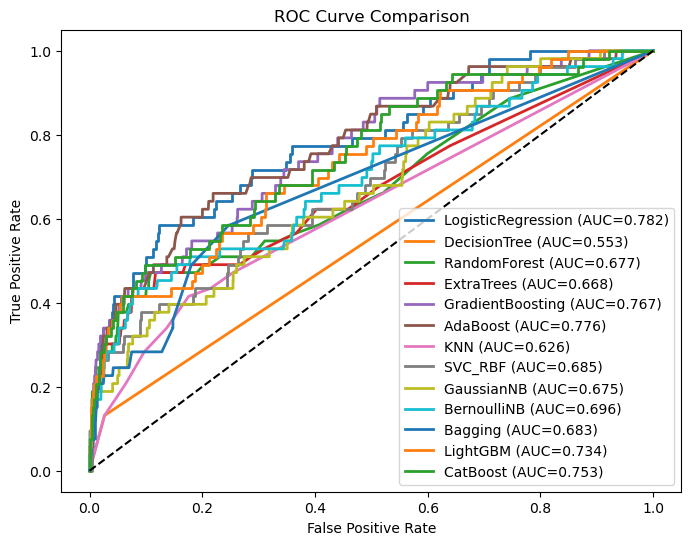

<Figure size 640x480 with 0 Axes>

In [20]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

for name, model in trained_models.items():

    if hasattr(model, "predict_proba"):
        prob = model.predict_proba(X_test_enc)[:,1]
    else:
        continue

    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)

    plt.plot(
        fpr,
        tpr,
        lw=2,
        label=f"{name} (AUC={auc:.3f})"
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison")
plt.legend()

plt.savefig(
    f"{OUT_DIR}/ROC_Curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.savefig("ROC curve")

In [21]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

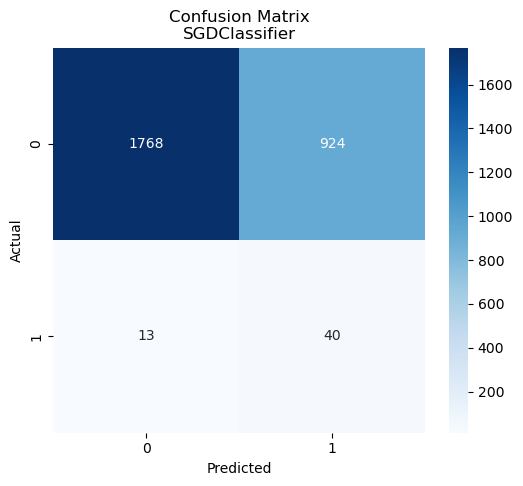

In [22]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

pred = best_model.predict(X_test_enc)

cm = confusion_matrix(y_test, pred)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.title(f"Confusion Matrix\n{best_model_name}")
plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.savefig(
    f"{OUT_DIR}/confusion_matrix.png",
    dpi=300
)

plt.show()

In [23]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        pred,
        digits=4
    )
)

              precision    recall  f1-score   support

           0     0.9927    0.6568    0.7905      2692
           1     0.0415    0.7547    0.0787        53

    accuracy                         0.6587      2745
   macro avg     0.5171    0.7057    0.4346      2745
weighted avg     0.9743    0.6587    0.7768      2745



In [24]:
with open(
    f"{OUT_DIR}/classification_report.txt",
    "w"
) as f:

    f.write(
        classification_report(
            y_test,
            pred,
            digits=4
        )
    )

In [25]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import mutual_info_classif

selector = SelectKBest(
    score_func=mutual_info_classif,
    k=50
)

X_train_fs = selector.fit_transform(
    X_train_bal,
    y_train_bal
)

X_test_fs = selector.transform(
    X_test_enc
)

selected_features = X_train_enc.columns[
    selector.get_support()
]

print(selected_features)

Index(['mat_age_years', 'birthorder', 'rural_residence', 'no_education',
       'poor_household', 'work_bin', 'sex_bin', 'high_birth_order',
       'multiple_birth', 'unimproved_water', 'unimproved_toilet', 'solid_fuel',
       'magegrp', 'medu', 'husbandedu', 'wealth', 'anc_cat',
       'region_Addis Ababa', 'region_Afar', 'region_Amhara',
       'region_Benishangul-Gumuz', 'region_Central Ethiopia',
       'region_Dire Dawa', 'region_Gambella', 'region_Harari', 'region_Oromia',
       'region_Sidama', 'region_Somali', 'region_South Ethiopia',
       'region_South West Ethiopia', 'region_Tigray',
       'birth_interval_cat_First birth (N/A)',
       'birth_interval_cat_Normal interval (>=24mo)',
       'birth_interval_cat_Short interval (<24mo)', 'facility_Health facility',
       'facility_Home', 'cs_No', 'cs_Yes', 'lbw_Low birth weight',
       'lbw_Missing', 'lbw_Normal birth weight',
       'delayed_breastfeeding_Missing', 'delayed_breastfeeding_No',
       'delayed_breastfeeding_

In [26]:
pd.DataFrame({
    "feature": selected_features
}).to_csv(
    f"{OUT_DIR}/selected_features.csv",
    index=False
)

In [29]:
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostClassifier

param_grid = {
    "depth":[4,6,8,10],
    "learning_rate":[0.01,0.03,0.05,0.1],
    "iterations":[300,500,800],
    "l2_leaf_reg":[1,3,5,7]
}

cb = CatBoostClassifier(
    verbose=0,
    random_state=42
)

search = RandomizedSearchCV(
    cb,
    param_grid,
    n_iter=20,
    scoring="roc_auc",
    cv=5,
    n_jobs=1,
    random_state=42
)

search.fit(
    X_train_bal,
    y_train_bal
)

best_cat = search.best_estimator_

print(search.best_params_)
print(search.best_score_)

{'learning_rate': 0.03, 'l2_leaf_reg': 1, 'iterations': 300, 'depth': 10}
0.998885335042932


In [37]:
from sklearn.metrics import roc_auc_score, average_precision_score
from scipy.special import expit

best_model = best_cat

prob = best_model.predict_proba(X_test_enc)[:,1]

print("Test ROC-AUC:", roc_auc_score(y_test, prob))
print("Test PR-AUC :", average_precision_score(y_test, prob))

Test ROC-AUC: 0.7358911099273878
Test PR-AUC : 0.16707661784444408


In [38]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.linear_model import LogisticRegression

param_grid = {
    "C": [0.001,0.01,0.1,1,10,100],
    "penalty": ["l1","l2"],
    "solver": ["liblinear"],
    "class_weight": ["balanced"]
}

lr = LogisticRegression(
    max_iter=5000,
    random_state=42
)

search = RandomizedSearchCV(
    lr,
    param_grid,
    n_iter=12,
    scoring="roc_auc",
    cv=5,
    random_state=42,
    n_jobs=1
)

search.fit(
    X_train_bal,
    y_train_bal
)

best_lr = search.best_estimator_

print(search.best_params_)

{'solver': 'liblinear', 'penalty': 'l1', 'class_weight': 'balanced', 'C': 0.1}


In [39]:
prob = best_lr.predict_proba(X_test_enc)[:,1]

print(
    "ROC_AUC:",
    roc_auc_score(y_test, prob)
)

print(
    "PR_AUC:",
    average_precision_score(y_test, prob)
)

ROC_AUC: 0.7802678796714234
PR_AUC: 0.16905112583606002


In [41]:
import numpy as np
from sklearn.metrics import f1_score

thresholds = np.arange(0.01, 0.99, 0.01)

best_threshold = 0
best_f1 = 0

for t in thresholds:

    pred = (prob >= t).astype(int)

    score = f1_score(y_test, pred)

    if score > best_f1:
        best_f1 = score
        best_threshold = t

print("Best threshold:", best_threshold)
print("Best F1:", best_f1)

Best threshold: 0.92
Best F1: 0.2647058823529412


In [43]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score
)

pred_final = (prob >= best_threshold).astype(int)

print("Accuracy",
      accuracy_score(y_test, pred_final))

print("Balanced Accuracy",
      balanced_accuracy_score(y_test, pred_final))

print("Precision",
      precision_score(y_test, pred_final))

print("Recall",
      recall_score(y_test, pred_final))

print("F1",
      f1_score(y_test, pred_final))

Accuracy 0.9635701275045537
Balanced Accuracy 0.657738512433766
Precision 0.21686746987951808
Recall 0.33962264150943394
F1 0.2647058823529412


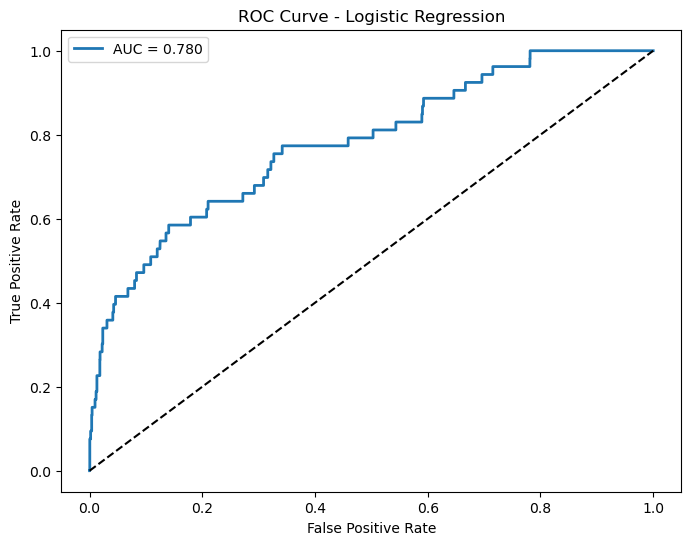

In [45]:
from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

fpr, tpr, _ = roc_curve(y_test, prob)

plt.figure(figsize=(8,6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"AUC = {roc_auc_score(y_test, prob):.3f}"
)

plt.plot([0,1], [0,1], "--", color="black")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()

plt.savefig(
    f"{OUT_DIR}/ROC_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

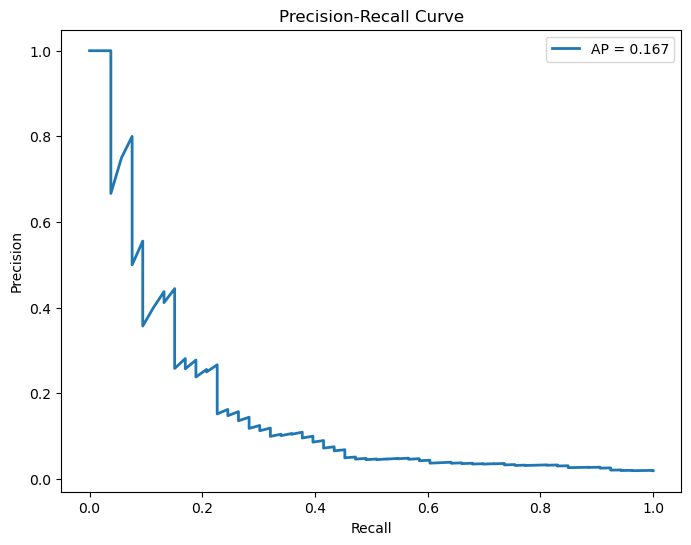

In [50]:
from sklearn.metrics import (
    precision_recall_curve,
    average_precision_score
)

precision, recall, _ = precision_recall_curve(
    y_test,
    prob
)

ap = average_precision_score(
    y_test,
    prob
)

plt.figure(figsize=(8,6))

plt.plot(
    recall,
    precision,
    linewidth=2,
    label=f"AP = {ap:.3f}"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve")
plt.legend()

plt.savefig(
    f"{OUT_DIR}/PR_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

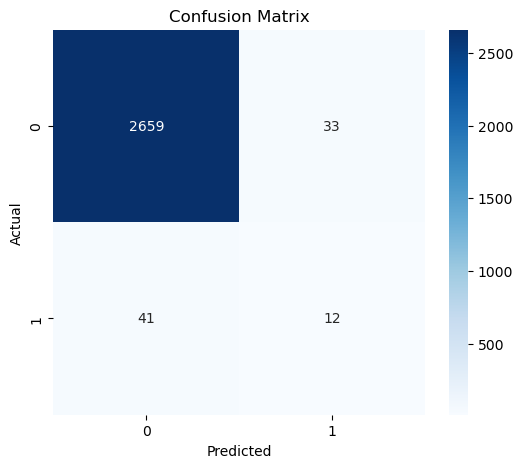

In [51]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

cm = confusion_matrix(
    y_test,
    pred_final
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.savefig(
    f"{OUT_DIR}/Confusion_Matrix.png",
    dpi=300
)

plt.show()

In [52]:
import pandas as pd
import numpy as np

coef_df = pd.DataFrame({
    "Feature": X_train_enc.columns,
    "Coefficient": best_lr.coef_[0]
})

coef_df["Odds_Ratio"] = np.exp(
    coef_df["Coefficient"]
)

coef_df = coef_df.sort_values(
    "Coefficient",
    ascending=False
)

In [53]:
coef_df.head(20)

,Feature,Coefficient,Odds_Ratio
46,delayed_breastfeeding_Missing,3.644368,38.258591
9,multiple_birth,2.734932,15.408697
21,region_Benishangul-Gumuz,0.571000,1.770036
31,region_Tigray,0.549553,1.732478
6,work_bin,0.347757,1.415888
26,region_Oromia,0.327277,1.387186
1,birthorder,0.294707,1.342733
0,mat_age_years,0.278551,1.321213
2,rural_residence,0.260317,1.297341
50,no_timely_pnc_baby_Missing,0.187889,1.206700


In [54]:
coef_df.tail(20)

,Feature,Coefficient,Odds_Ratio
16,wealth,0.000000,1.000000
10,unimproved_water,-0.010477,0.989578
27,region_Sidama,-0.055661,0.945860
14,medu,-0.098741,0.905977
15,husbandedu,-0.107969,0.897655
38,facility_Other,-0.151066,0.859791
55,no_timely_pnc_mother_No,-0.241216,0.785672
22,region_Central Ethiopia,-0.270890,0.762700
39,cs_No,-0.399900,0.670387
47,delayed_breastfeeding_No,-0.421143,0.656296


In [55]:
coef_df.to_csv(
    f"{OUT_DIR}/Odds_Ratios.csv",
    index=False
)

In [56]:
from sklearn.inspection import permutation_importance

perm = permutation_importance(
    best_lr,
    X_test_enc,
    y_test,
    scoring="roc_auc",
    n_repeats=20,
    random_state=42
)

perm_imp = pd.DataFrame({
    "Feature": X_test_enc.columns,
    "Importance": perm.importances_mean
})

perm_imp = perm_imp.sort_values(
    "Importance",
    ascending=False
)

perm_imp.head(30)

,Feature,Importance
46,delayed_breastfeeding_Missing,0.093517
33,birth_interval_cat_Normal interval (>=24mo),0.018035
49,delayed_breastfeeding_Yes,0.017411
44,lbw_Normal birth weight,0.016209
9,multiple_birth,0.011264
8,high_birth_order,0.007955
47,delayed_breastfeeding_No,0.006498
39,cs_No,0.006336
51,no_timely_pnc_baby_No,0.005555
1,birthorder,0.005503


In [57]:
import shap

explainer = shap.LinearExplainer(
    best_lr,
    X_train_enc
)

shap_values = explainer.shap_values(
    X_test_enc
)

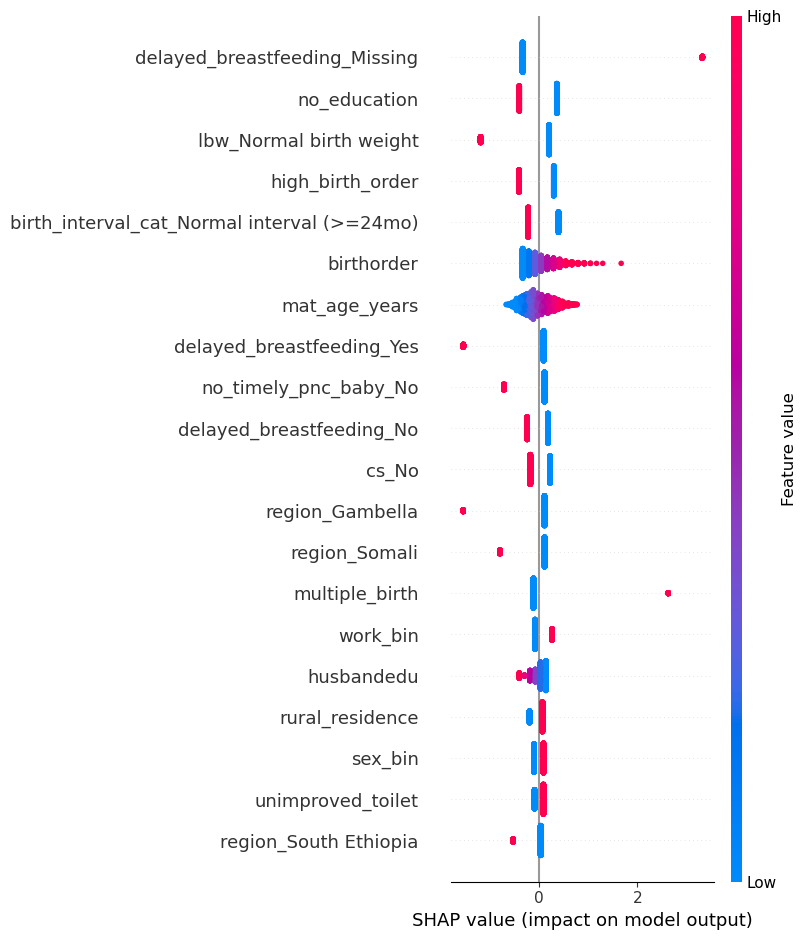

In [58]:
shap.summary_plot(
    shap_values,
    X_test_enc,
    show=False
)

plt.savefig(
    f"{OUT_DIR}/SHAP_Summary.png",
    dpi=300,
    bbox_inches="tight"
)

In [59]:
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[0],
        base_values=explainer.expected_value,
        data=X_test_enc.iloc[0],
        feature_names=X_test_enc.columns
    ),
    show=False
)

plt.savefig(
    f"{OUT_DIR}/SHAP_Waterfall.png",
    dpi=300,
    bbox_inches="tight"
)

In [60]:
top_feature = perm_imp.iloc[0]["Feature"]

In [61]:
shap.dependence_plot(
    top_feature,
    shap_values,
    X_test_enc,
    show=False
)

plt.savefig(
    f"{OUT_DIR}/SHAP_Dependence.png",
    dpi=300,
    bbox_inches="tight"
)


In [63]:
from sklearn.calibration import calibration_curve
from sklearn.metrics import brier_score_loss

obs, pred_prob = calibration_curve(
    y_test,
    prob,
    n_bins=10
)

brier = brier_score_loss(
    y_test,
    prob
)

print("Brier Score:", brier)

Brier Score: 0.018974002168258102


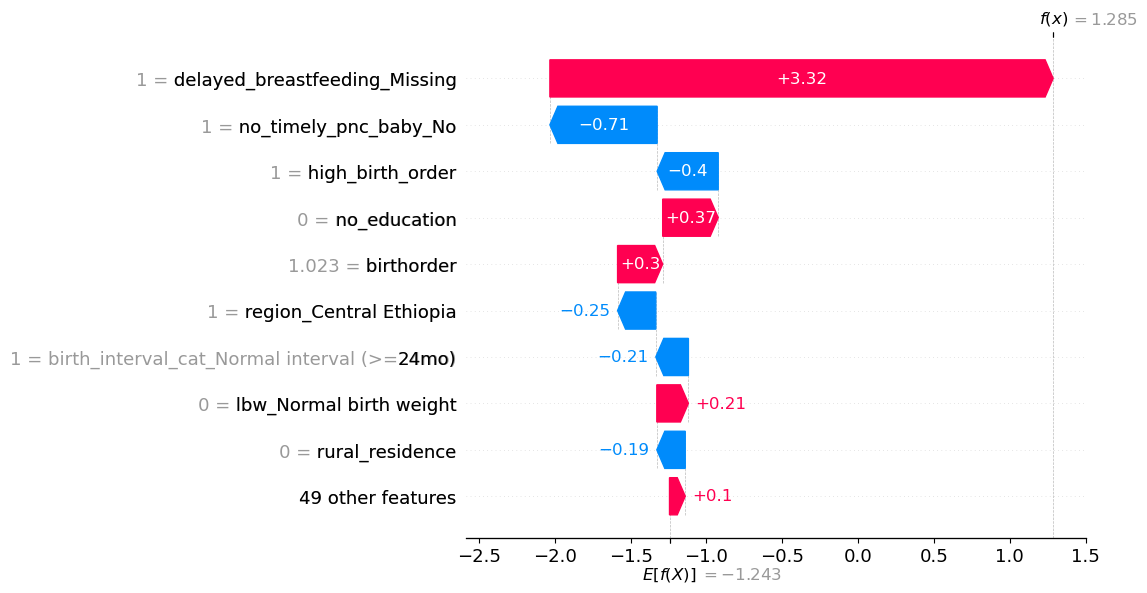

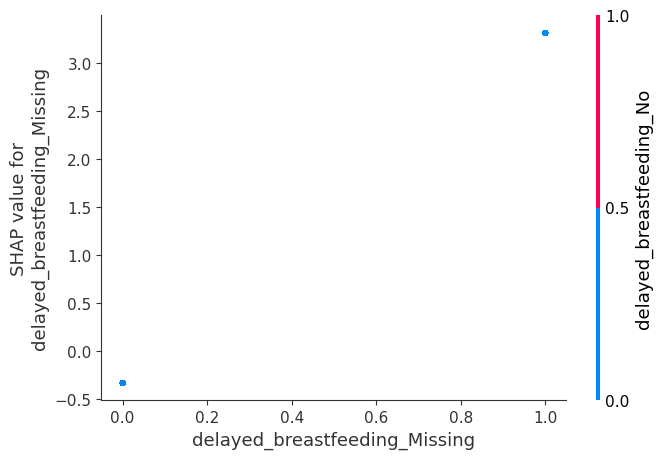

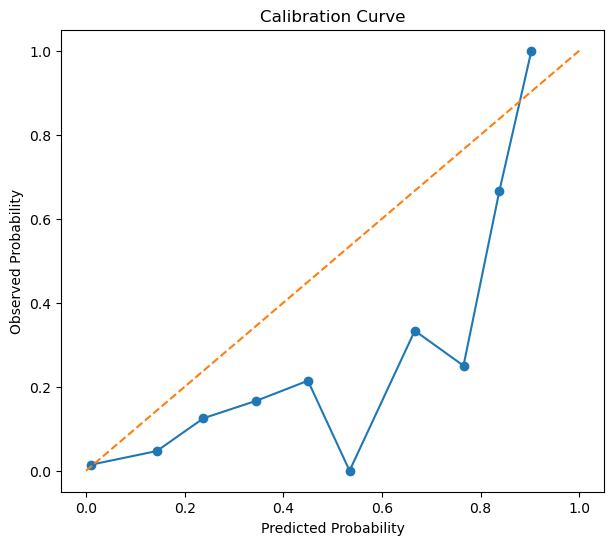

In [64]:
plt.figure(figsize=(7,6))

plt.plot(pred_prob, obs, marker="o")

plt.plot([0,1],[0,1],"--")

plt.xlabel("Predicted Probability")
plt.ylabel("Observed Probability")
plt.title("Calibration Curve")

plt.savefig(
    f"{OUT_DIR}/Calibration_Curve.png",
    dpi=300
)

plt.show()

In [46]:
from sklearn.metrics import f1_score
import numpy as np

prob = best_cat.predict_proba(
    X_test_enc
)[:,1]

thresholds = np.arange(
    0.05,
    0.95,
    0.01
)

scores = []

for t in thresholds:

    pred_t = (prob >= t).astype(int)

    scores.append(
        f1_score(y_test, pred_t)
    )

best_t = thresholds[np.argmax(scores)]

print("Best threshold:", best_t)

Best threshold: 0.26000000000000006


In [47]:
best_threshold = 0.26

from scipy.special import expit

if hasattr(best_model, "predict_proba"):
    prob = best_model.predict_proba(X_test_enc)[:, 1]

elif hasattr(best_model, "decision_function"):
    prob = expit(
        best_model.decision_function(X_test_enc)
    )

else:
    prob = best_model.predict(X_test_enc)



In [48]:
pred_final = (prob >= 0.26).astype(int)

In [49]:
from sklearn.linear_model import SGDClassifier

best_model = SGDClassifier(
    loss="log_loss",
    class_weight="balanced",
    random_state=42
)

best_model.fit(
    X_train_bal,
    y_train_bal
)

,loss,'log_loss'
,penalty,'l2'
,alpha,0.0001
,l1_ratio,0.15
,fit_intercept,True
,max_iter,1000
,tol,0.001
,shuffle,True
,verbose,0
,epsilon,0.1
,n_jobs,None


NameError: name 'get_probabilities' is not defined